<a href="https://colab.research.google.com/github/Ranjitkumarmuduli/tomato-disease-detection/blob/main/07_tomatoleafnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 7 – TomatoLeafNet: Own trained model
A new lightweight CNN **designed and trained from scratch** for tomato leaf diseases.
- **Multi-scale blocks**: 3×3, 5×5 and dilated 3×3 filters side by side → small spots *and* spread-out symptoms
- **SE attention**: learns which feature channels matter most
- **Depthwise convolutions + residual links**: small and fast
- **Knowledge distillation**: optionally learns from our EfficientNet-B0

In [ ]:
# 1. Install libraries
!pip -q install timm kagglehub

In [ ]:
# 2. Imports and GPU check
#`TF` (torchvision functional) is used later for the robustness test (blur, brightness, rotation).
import os, time, json, copy, random, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import timm, kagglehub
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import torchvision.transforms.v2.functional as TF
from sklearn.metrics import accuracy_score, f1_score, classification_report

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU – switch the runtime to T4 GPU!")

def set_seed(s=42):                       # same seed = reproducible results
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Device: Tesla T4


In [ ]:
# 3. Drive, dataset and class names
#Same project folder and the **same saved split** as Steps 1–3, so the new model is compared.
from google.colab import drive
drive.mount('/content/drive')

PROJ = "/content/drive/MyDrive/tomato_project"
base = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
ROOT = f"{base}/plantvillage dataset/color"

CLASSES = pd.read_csv(f"{PROJ}/splits/classes.csv", header=None)[0].tolist()
NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES, "classes")

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
10 classes


In [ ]:
# 4. Data loaders
#Batch size is 128 (instead of 64) because the new model is small and fits more images per step.
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.RandomRotation(20), T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])

class TomatoLeafDataset(Dataset):
    def __init__(self, csv_file, transform):
        self.data, self.transform = pd.read_csv(csv_file), transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, i):
        r = self.data.iloc[i]
        return self.transform(Image.open(f"{ROOT}/{r.relpath}").convert("RGB")), int(r.label)

BATCH = 128
kw = dict(batch_size=BATCH, num_workers=2, pin_memory=True)
train_dl = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/train.csv", train_tf), shuffle=True, drop_last=True, **kw)
val_dl   = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/val.csv", eval_tf), **kw)
test_dl  = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/test.csv", eval_tf), **kw)
print("train / val / test batches:", len(train_dl), len(val_dl), len(test_dl))

train / val / test batches: 99 22 22


## 5. TomatoLeafNet architecture
- **SEBlock** – squeeze-and-excitation: gives each feature channel an importance weight (0–1)
- **MSBlock** – three depthwise branches (3×3, 5×5, dilated 3×3) look at the leaf at different scales →
  combined → 1×1 fuse → SE attention → residual (shortcut) connection
- **TomatoLeafNet** – stem → 4 stages (32, 64, 128, 256 channels; 1, 2, 3, 2 blocks) → global pooling → 10 classes

The `multiscale` and `se` switches turn parts off for the ablation study.

In [ ]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation: learns a weight (0-1) for every channel."""
    def __init__(self, ch, r=4):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, ch // r, 1), nn.SiLU(),
                                nn.Conv2d(ch // r, ch, 1), nn.Sigmoid())
    def forward(self, x):
        return x * self.fc(x)

class MSBlock(nn.Module):
    """Multi-scale depthwise block with optional SE attention and a residual connection."""
    def __init__(self, c_in, c_out, stride=1, multiscale=True, se=True):
        super().__init__()
        def dw(k, d=1):   # depthwise conv: one filter per channel (cheap)
            return nn.Sequential(nn.Conv2d(c_in, c_in, k, stride, padding=d * (k // 2), dilation=d, groups=c_in, bias=False),
                                 nn.BatchNorm2d(c_in), nn.SiLU())
        self.branches = nn.ModuleList([dw(3), dw(5), dw(3, d=2)] if multiscale else [dw(3)])
        self.fuse = nn.Sequential(nn.Conv2d(c_in * len(self.branches), c_out, 1, bias=False), nn.BatchNorm2d(c_out))
        self.se = SEBlock(c_out) if se else nn.Identity()
        self.skip = (nn.Identity() if (stride == 1 and c_in == c_out) else
                     nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out)))
        self.act = nn.SiLU()
    def forward(self, x):
        y = torch.cat([b(x) for b in self.branches], dim=1)   # multi-scale features side by side
        y = self.se(self.fuse(y))                             # fuse, then channel attention
        return self.act(y + self.skip(x))                     # residual connection

class TomatoLeafNet(nn.Module):
    """Lightweight multi-scale attention CNN for tomato leaf disease classification."""
    def __init__(self, num_classes=10, multiscale=True, se=True, widths=(32, 64, 128, 256), depths=(1, 2, 3, 2)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.SiLU())  # 224 -> 112
        layers, c = [], 32
        for w, d in zip(widths, depths):
            for i in range(d):
                layers.append(MSBlock(c, w, stride=2 if i == 0 else 1, multiscale=multiscale, se=se))
                c = w
        self.features = nn.Sequential(*layers)   # 112 -> 56 -> 28 -> 14 -> 7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(c, num_classes))
    def forward_features(self, x):
        return self.features(self.stem(x))
    def forward_head(self, f):
        return self.head(f)
    def forward(self, x):
        return self.forward_head(self.forward_features(x))

for ms, se in [(False, False), (True, False), (False, True), (True, True)]:
    n = sum(p.numel() for p in TomatoLeafNet(NUM_CLASSES, ms, se).parameters()) / 1e6
    print(f"multiscale={ms!s:5} SE={se!s:5}: {n:.3f} M parameters")

multiscale=False SE=False: 0.206 M parameters
multiscale=True  SE=False: 0.531 M parameters
multiscale=False SE=True : 0.302 M parameters
multiscale=True  SE=True : 0.627 M parameters


## 6. Ablation runs
| Run | Multi-scale | SE | Distillation |
|---|---|---|---|
| A1 | ✗ | ✗ | ✗ |
| A2 | ✓ | ✗ | ✗ |
| A3 | ✗ | ✓ | ✗ |
| A4 (full) | ✓ | ✓ | ✗ |
| A5 (full + KD) | ✓ | ✓ | ✓ |

All runs: **25 epochs from scratch**, AdamW, one-cycle learning rate (max 3×10⁻³), label smoothing 0.1,
mixed precision, seed 42. The main model (A4) runs first.

In [ ]:
EPOCHS = 25
RUNS = {
    "tln_A1_plain":    dict(multiscale=False, se=False, kd=False),
    "tln_A2_ms":       dict(multiscale=True,  se=False, kd=False),
    "tln_A3_se":       dict(multiscale=False, se=True,  kd=False),
    "tln_A4_full":     dict(multiscale=True,  se=True,  kd=False),
    "tln_A5_full_kd":  dict(multiscale=True,  se=True,  kd=True),
}
RUNS_TO_DO = ["tln_A4_full", "tln_A5_full_kd", "tln_A1_plain", "tln_A2_ms", "tln_A3_se"]   # main model first

## 7. Training and evaluation functions
- **From scratch**: no ImageNet weights – the model learns only from tomato leaves.
- **One-cycle learning rate**: rises for the first 15% of training, then slowly falls (works well from scratch).
- **Knowledge distillation (KD)**: the student (TomatoLeafNet) learns from the true labels *and* from the
  softened predictions of the teacher (our EfficientNet-B0). Temperature T = 4, weight α = 0.5.
- The best epoch (lowest validation loss) is saved to Drive, then scored on the **test set** and added to
  `results/summary_tln.csv`.

In [ ]:
def kd_loss(s_logits, t_logits, y, T=4.0, alpha=0.5):
    ce = F.cross_entropy(s_logits, y, label_smoothing=0.1)                               # learn from labels
    kl = F.kl_div(F.log_softmax(s_logits / T, 1), F.softmax(t_logits / T, 1), reduction="batchmean") * T * T  # learn from teacher
    return alpha * ce + (1 - alpha) * kl

def load_teacher():
    t = timm.create_model("efficientnet_b0", pretrained=False, num_classes=NUM_CLASSES)
    t.load_state_dict(torch.load(f"{PROJ}/weights/efficientnet_b0.pt", map_location="cpu"))
    return t.to(DEVICE).eval()

def train_tln(name, multiscale, se, kd, epochs=EPOCHS):
    set_seed(42)
    model = TomatoLeafNet(NUM_CLASSES, multiscale, se).to(DEVICE)
    teacher = load_teacher() if kd else None
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, epochs=epochs, steps_per_epoch=len(train_dl), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    ce = nn.CrossEntropyLoss(label_smoothing=0.1)
    hist, best, start = [], float("inf"), time.time()
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); n = c = 0; ls = 0.0
        for x, y in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
                out = model(x)
                if kd:
                    with torch.no_grad():
                        t_out = teacher(x)
                    loss = kd_loss(out.float(), t_out.float(), y)
                else:
                    loss = ce(out, y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            ls += loss.item() * len(y); c += (out.argmax(1) == y).sum().item(); n += len(y)
        vl, va = evaluate_loss(model)
        hist.append(dict(epoch=ep, train_loss=ls / n, train_acc=c / n, val_loss=vl, val_acc=va))
        flag = ""
        if vl < best:
            best, flag = vl, "  <- saved"
            torch.save(model.state_dict(), f"{PROJ}/weights/{name}.pt")
        print(f"[{name}] epoch {ep:2d}/{epochs} | train acc {c / n:.4f} | val acc {va:.4f} | val loss {vl:.4f} | {time.time() - t0:.0f}s{flag}")
    minutes = (time.time() - start) / 60
    pd.DataFrame(hist).to_csv(f"{PROJ}/results/history_{name}.csv", index=False)
    model.load_state_dict(torch.load(f"{PROJ}/weights/{name}.pt"))
    return model, minutes

@torch.no_grad()
def evaluate_loss(model, loader=None):
    model.eval(); loader = loader or val_dl; n = c = 0; ls = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            out = model(x)
        ls += F.cross_entropy(out.float(), y, label_smoothing=0.1).item() * len(y); c += (out.argmax(1) == y).sum().item(); n += len(y)
    return ls / n, c / n

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            ps += model(x.to(DEVICE)).argmax(1).cpu().tolist()
        ys += y.tolist()
    return np.array(ys), np.array(ps)

@torch.no_grad()
def ms_per_image(model, device, runs=30):
    model = copy.deepcopy(model).to(device).eval(); x = torch.randn(1, 3, 224, 224, device=device)
    for _ in range(5): model(x)
    if device == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(runs): model(x)
    if device == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / runs * 1000

def record(name, model, minutes):
    y, p = predict(model, test_dl)
    row = dict(model=name, test_accuracy=round(accuracy_score(y, p), 4), macro_f1=round(f1_score(y, p, average="macro"), 4),
               params_million=round(sum(q.numel() for q in model.parameters()) / 1e6, 3),
               size_MB=round(os.path.getsize(f"{PROJ}/weights/{name}.pt") / 1e6, 2), train_minutes=round(minutes, 1),
               gpu_ms=round(ms_per_image(model, DEVICE), 1) if DEVICE == "cuda" else None, cpu_ms=round(ms_per_image(model, "cpu", 10), 1))
    pd.DataFrame(classification_report(y, p, target_names=CLASSES, output_dict=True)).T.to_csv(f"{PROJ}/results/report_{name}.csv")
    f = f"{PROJ}/results/summary_tln.csv"
    old = pd.read_csv(f) if os.path.exists(f) else pd.DataFrame(columns=row.keys())
    pd.concat([old[old.model != name], pd.DataFrame([row])]).to_csv(f, index=False)
    print(row)

## 8. Train all runs
Each finished run is saved to Drive. If Colab disconnects, run Cells 1–7 again and then this cell:
finished runs are skipped automatically.

In [ ]:
summary_file = f"{PROJ}/results/summary_tln.csv"
done = set(pd.read_csv(summary_file).model) if os.path.exists(summary_file) else set()
for name in RUNS_TO_DO:
    if name in done:
        print("already done:", name); continue
    model, minutes = train_tln(name, **RUNS[name])
    record(name, model, minutes)
    del model; torch.cuda.empty_cache()

[tln_A4_full] epoch  1/25 | train acc 0.4897 | val acc 0.6999 | val loss 1.2236 | 119s  <- saved
[tln_A4_full] epoch  2/25 | train acc 0.7840 | val acc 0.8038 | val loss 0.9986 | 86s  <- saved
[tln_A4_full] epoch  3/25 | train acc 0.8737 | val acc 0.8843 | val loss 0.7641 | 84s  <- saved
[tln_A4_full] epoch  4/25 | train acc 0.9162 | val acc 0.9052 | val loss 0.7112 | 82s  <- saved
[tln_A4_full] epoch  5/25 | train acc 0.9362 | val acc 0.8938 | val loss 0.7459 | 84s
[tln_A4_full] epoch  6/25 | train acc 0.9560 | val acc 0.9607 | val loss 0.5993 | 85s  <- saved
[tln_A4_full] epoch  7/25 | train acc 0.9601 | val acc 0.9313 | val loss 0.6565 | 83s
[tln_A4_full] epoch  8/25 | train acc 0.9675 | val acc 0.9614 | val loss 0.5899 | 82s  <- saved
[tln_A4_full] epoch  9/25 | train acc 0.9722 | val acc 0.9640 | val loss 0.5879 | 83s  <- saved
[tln_A4_full] epoch 10/25 | train acc 0.9754 | val acc 0.9798 | val loss 0.5487 | 82s  <- saved
[tln_A4_full] epoch 11/25 | train acc 0.9808 | val acc 0.97

/tmp/ipykernel_2213/3109498506.py:84: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old[old.model != name], pd.DataFrame([row])]).to_csv(f, index=False)


{'model': 'tln_A4_full', 'test_accuracy': 0.9941, 'macro_f1': 0.9927, 'params_million': 0.627, 'size_MB': 2.63, 'train_minutes': 35.8, 'gpu_ms': 5.5, 'cpu_ms': 16.2}
[tln_A5_full_kd] epoch  1/25 | train acc 0.4968 | val acc 0.6870 | val loss 1.2354 | 91s  <- saved
[tln_A5_full_kd] epoch  2/25 | train acc 0.7736 | val acc 0.7502 | val loss 1.1134 | 89s  <- saved
[tln_A5_full_kd] epoch  3/25 | train acc 0.8777 | val acc 0.8971 | val loss 0.7470 | 90s  <- saved
[tln_A5_full_kd] epoch  4/25 | train acc 0.9135 | val acc 0.9181 | val loss 0.6979 | 90s  <- saved
[tln_A5_full_kd] epoch  5/25 | train acc 0.9430 | val acc 0.8898 | val loss 0.7711 | 90s
[tln_A5_full_kd] epoch  6/25 | train acc 0.9525 | val acc 0.9398 | val loss 0.6463 | 91s  <- saved
[tln_A5_full_kd] epoch  7/25 | train acc 0.9649 | val acc 0.9412 | val loss 0.6464 | 93s
[tln_A5_full_kd] epoch  8/25 | train acc 0.9691 | val acc 0.9629 | val loss 0.5920 | 90s  <- saved
[tln_A5_full_kd] epoch  9/25 | train acc 0.9722 | val acc 0.97

## 9. Comparison table

In [ ]:
tln = pd.read_csv(f"{PROJ}/results/summary_tln.csv")
old = pd.read_csv(f"{PROJ}/results/comparison.csv")
table = pd.concat([old, tln], ignore_index=True)[["model", "test_accuracy", "macro_f1", "params_million", "size_MB", "cpu_ms", "train_minutes"]]
table.to_csv(f"{PROJ}/results/comparison_with_tln.csv", index=False)
table.sort_values("macro_f1", ascending=False)

,model,test_accuracy,macro_f1,params_million,size_MB,cpu_ms,train_minutes
0,efficientnet_b0,0.9974,0.9966,4.020,16.40,44.9,14.2
5,tln_A5_full_kd,0.9949,0.9942,0.627,2.63,17.6,36.8
1,mobilenetv3_large_100,0.9941,0.9934,4.210,17.10,25.2,12.9
4,tln_A4_full,0.9941,0.9927,0.627,2.63,16.2,35.8
2,resnet50,0.9923,0.9903,23.530,94.40,133.0,14.4
7,tln_A2_ms,0.9927,0.9903,0.531,2.23,18.6,35.3
8,tln_A3_se,0.9908,0.9886,0.302,1.29,10.8,34.8
6,tln_A1_plain,0.9897,0.9880,0.206,0.89,8.0,34.2
3,baseline_cnn,0.9467,0.9337,0.390,1.60,40.6,12.1


### Validation accuracy of the five TomatoLeafNet runs

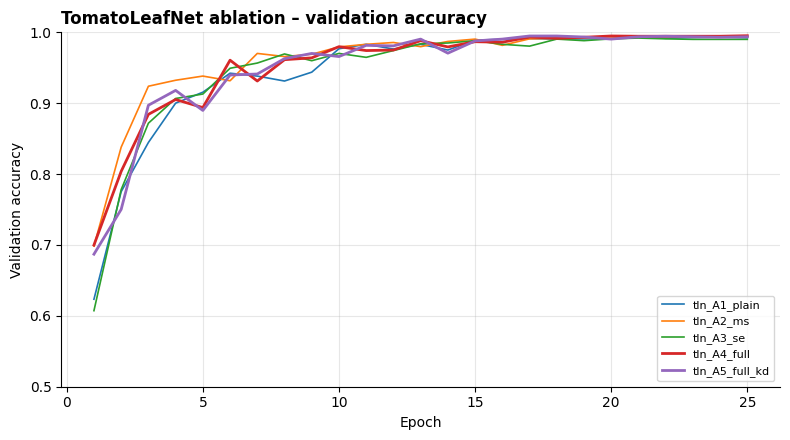

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in [n for n in RUNS if os.path.exists(f"{PROJ}/results/history_{n}.csv")]:
    h = pd.read_csv(f"{PROJ}/results/history_{name}.csv")
    ax.plot(h.epoch, h.val_acc, label=name, lw=2 if "A4" in name or "A5" in name else 1.2)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy"); ax.set_ylim(0.5, 1.0)
ax.set_title("TomatoLeafNet ablation – validation accuracy", loc="left", fontweight="bold")
ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/tln_ablation_curves.png", dpi=300); plt.show()

## 10. Robustness test
Every test image is changed in a controlled way (darker, brighter, low contrast, blurred, noisy,
rotated 30°, partly covered), then all 9 models are scored again (macro F1).
This shows how each model copes with **poor phone photos** and answers research question RQ6.
Takes about 10–15 minutes.

In [ ]:
class BaselineCNN(nn.Module):   # identical to Step 2, needed to load its weights
    def __init__(self, num_classes):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def load_any(name):
    if name.startswith("tln_"):
        cfg = RUNS[name]; m = TomatoLeafNet(NUM_CLASSES, cfg["multiscale"], cfg["se"])
    elif name == "baseline_cnn":
        m = BaselineCNN(NUM_CLASSES)
    else:
        m = timm.create_model(name, pretrained=False, num_classes=NUM_CLASSES)
    m.load_state_dict(torch.load(f"{PROJ}/weights/{name}.pt", map_location="cpu"))
    return m.to(DEVICE).eval()

# test images WITHOUT normalisation, so the changes are applied to real pixel values (0-1)
raw_dl = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/test.csv", T.Compose([T.Resize((224, 224)), T.ToTensor()])), batch_size=128, num_workers=2)
mean_t, std_t = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1), torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1)

def occlude(x, size=60, seed=0):          # black 60x60 square at a random (fixed) place
    g = torch.Generator().manual_seed(seed); x = x.clone()
    for i in range(len(x)):
        r, c = torch.randint(0, 224 - size, (2,), generator=g).tolist(); x[i, :, r:r + size, c:c + size] = 0
    return x

PERTURB = {
    "clean":          lambda x: x,
    "dark (x0.6)":    lambda x: TF.adjust_brightness(x, 0.6),
    "bright (x1.4)":  lambda x: TF.adjust_brightness(x, 1.4).clamp(0, 1),
    "low contrast":   lambda x: TF.adjust_contrast(x, 0.6),
    "blur":           lambda x: TF.gaussian_blur(x, kernel_size=9, sigma=2.0),
    "noise":          lambda x: (x + 0.08 * torch.randn_like(x)).clamp(0, 1),
    "rotate 30°":     lambda x: TF.rotate(x, 30),
    "occlusion":      lambda x: occlude(x),
}

@torch.no_grad()
def robustness(model):
    res = {}
    for pname, fn in PERTURB.items():
        torch.manual_seed(0); ys, ps = [], []
        for x, y in raw_dl:
            x = fn(x.to(DEVICE)); x = (x - mean_t) / std_t
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
                ps += model(x).argmax(1).cpu().tolist()
            ys += y.tolist()
        res[pname] = round(f1_score(ys, ps, average="macro"), 4)
    return res

MODELS_ROB = ["baseline_cnn", "mobilenetv3_large_100", "efficientnet_b0", "resnet50"] + [n for n in RUNS if os.path.exists(f"{PROJ}/weights/{n}.pt")]
rob = {}
for name in MODELS_ROB:
    rob[name] = robustness(load_any(name)); print(name, rob[name])
rob = pd.DataFrame(rob).T
rob["mean_perturbed"] = rob.drop(columns="clean").mean(axis=1).round(4)
rob["drop_vs_clean"] = (rob["clean"] - rob["mean_perturbed"]).round(4)
rob.to_csv(f"{PROJ}/results/robustness.csv")
rob.sort_values("mean_perturbed", ascending=False)

baseline_cnn {'clean': 0.9337, 'dark (x0.6)': 0.7738, 'bright (x1.4)': 0.8586, 'low contrast': 0.6913, 'blur': 0.3, 'noise': 0.3368, 'rotate 30°': 0.9431, 'occlusion': 0.9315}
mobilenetv3_large_100 {'clean': 0.9934, 'dark (x0.6)': 0.9813, 'bright (x1.4)': 0.9917, 'low contrast': 0.9751, 'blur': 0.2733, 'noise': 0.0657, 'rotate 30°': 0.992, 'occlusion': 0.9888}
efficientnet_b0 {'clean': 0.9966, 'dark (x0.6)': 0.9954, 'bright (x1.4)': 0.9906, 'low contrast': 0.994, 'blur': 0.1844, 'noise': 0.0854, 'rotate 30°': 0.9951, 'occlusion': 0.9951}
resnet50 {'clean': 0.9903, 'dark (x0.6)': 0.984, 'bright (x1.4)': 0.9809, 'low contrast': 0.9838, 'blur': 0.2219, 'noise': 0.6987, 'rotate 30°': 0.9864, 'occlusion': 0.981}
tln_A1_plain {'clean': 0.988, 'dark (x0.6)': 0.9532, 'bright (x1.4)': 0.9689, 'low contrast': 0.9152, 'blur': 0.845, 'noise': 0.2763, 'rotate 30°': 0.9879, 'occlusion': 0.9766}
tln_A2_ms {'clean': 0.9903, 'dark (x0.6)': 0.9765, 'bright (x1.4)': 0.9792, 'low contrast': 0.9703, 'blur'

,clean,dark (x0.6),bright (x1.4),low contrast,blur,noise,rotate 30°,occlusion,mean_perturbed,drop_vs_clean
tln_A4_full,0.9927,0.9665,0.9833,0.9687,0.9048,0.5358,0.9864,0.9714,0.9024,0.0903
tln_A5_full_kd,0.9942,0.9664,0.9826,0.9645,0.8918,0.4972,0.9855,0.9699,0.8940,0.1002
tln_A2_ms,0.9903,0.9765,0.9792,0.9703,0.8906,0.4438,0.9891,0.9724,0.8888,0.1015
tln_A3_se,0.9886,0.9468,0.9745,0.9422,0.8412,0.4373,0.9835,0.9674,0.8704,0.1182
tln_A1_plain,0.9880,0.9532,0.9689,0.9152,0.8450,0.2763,0.9879,0.9766,0.8462,0.1418
resnet50,0.9903,0.9840,0.9809,0.9838,0.2219,0.6987,0.9864,0.9810,0.8338,0.1565
mobilenetv3_large_100,0.9934,0.9813,0.9917,0.9751,0.2733,0.0657,0.9920,0.9888,0.7526,0.2408
efficientnet_b0,0.9966,0.9954,0.9906,0.9940,0.1844,0.0854,0.9951,0.9951,0.7486,0.2480
baseline_cnn,0.9337,0.7738,0.8586,0.6913,0.3000,0.3368,0.9431,0.9315,0.6907,0.2430


## 11. Grad-CAM for TomatoLeafNet
Same method as Step 3, on the final 7×7 feature map of our own model.
Checks that TomatoLeafNet also looks at the leaf and lesions, not the background.

Best TomatoLeafNet run: tln_A5_full_kd


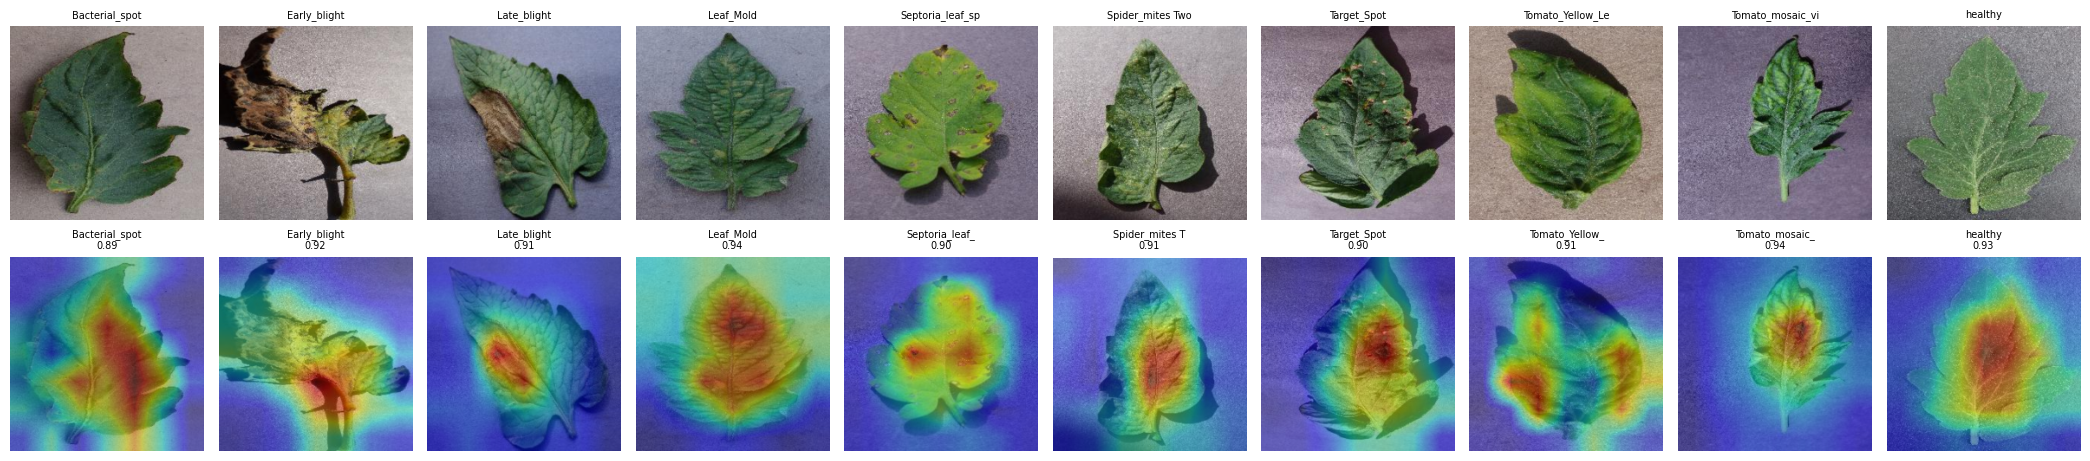

In [ ]:
BEST_TLN = tln.sort_values("macro_f1", ascending=False).iloc[0].model
model = load_any(BEST_TLN); print("Best TomatoLeafNet run:", BEST_TLN)

def grad_cam(model, t):
    x = t.unsqueeze(0).to(DEVICE)
    with torch.enable_grad():
        feats = model.forward_features(x); feats.retain_grad()
        logits = model.forward_head(feats); cls = int(logits.argmax(1))
        model.zero_grad(); logits[0, cls].backward()
    w = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), cls, float(torch.softmax(logits.detach(), 1)[0, cls])

test_df = pd.read_csv(f"{PROJ}/splits/test.csv")
ex = test_df.groupby("label").head(1).sort_values("label")
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2.1 * NUM_CLASSES, 4.8))
for k, (_, r) in enumerate(ex.iterrows()):
    t = eval_tf(Image.open(f"{ROOT}/{r.relpath}").convert("RGB")); cam, cls, pr = grad_cam(model, t)
    img = (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
    axes[0, k].imshow(img); axes[0, k].set_title(CLASSES[r.label][:16], fontsize=7)
    axes[1, k].imshow(img); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].set_title(f"{CLASSES[cls][:14]}\n{pr:.2f}", fontsize=7)
    for a in axes[:, k]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/gradcam_{BEST_TLN}.png", dpi=300); plt.show()

## 12. Export TomatoLeafNet for the app
Saves `app_model_v2/` with the new model, its settings and the knowledge base (used in Step 9).

In [ ]:
APP2 = f"{PROJ}/app_model_v2"; os.makedirs(APP2, exist_ok=True)
shutil.copy(f"{PROJ}/weights/{BEST_TLN}.pt", f"{APP2}/model.pt")
shutil.copy(f"{PROJ}/app_model/disease_info.json", APP2)
cfg = {"model_name": "tomatoleafnet", "run": BEST_TLN, "multiscale": RUNS[BEST_TLN]["multiscale"], "se": RUNS[BEST_TLN]["se"],
       "classes": CLASSES, "img_size": 224, "mean": MEAN, "std": STD, "confidence_threshold": 0.6}
json.dump(cfg, open(f"{APP2}/config.json", "w"), indent=2)
print(os.listdir(APP2)); print(cfg)

['model.pt', 'disease_info.json', 'config.json']
{'model_name': 'tomatoleafnet', 'run': 'tln_A5_full_kd', 'multiscale': True, 'se': True, 'classes': ['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Septoria_leaf_spot', 'Spider_mites Two-spotted_spider_mite', 'Target_Spot', 'Tomato_Yellow_Leaf_Curl_Virus', 'Tomato_mosaic_virus', 'healthy'], 'img_size': 224, 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'confidence_threshold': 0.6}
